# Predictive Analytics in Business

##### Intro

Companies’ ability to forecast future earnings is essential because earnings is a significant driver and indication of the company’s performance and will directly impact investor decisions. Investors can use earnings forecasts to determine the intrinsic value of the company’s stock and influences their decisions to buy or sell their shares in the company. Additionally, the company itself will use internal earnings forecast to help drive strategic business decisions such as budgeting, capital allocation, managing revenue, assets, and liabilities (expenses). 

DuPont analysis, as shown in Soliman (2008), highlights how the individual components of a firm’s financial performance can help explain and predict future earnings. These components can assist financial analysts in generating more accurate earnings forecasts. This report aims to predict corporate earnings by applying financial statement analysis based on the DuPont model. The DuPont forecasts future earnings as return on equity (ROE) into three main components: profit margin, asset turnover and financial leverage. Together, these components provide a comprehensive view of a firm's profitability, operational efficiency, and capital structure, which are critical in understanding and forecasting future earnings performance.
For this report, we use a dataset containing financial information from a range of firms. By analysing each firm's historical financial data, we can calculate key financial metrics and use them to forecast future earnings. The accounting dataset provided contains the following variables: 
* gvkey = company id
* datadate
* fyear = fiscal year
* at = total assets
* ceq = common/ordinary equity total
* che = cash and short-term investments
* csho = common shares outstanding
* dlc = debt in current liabilities – total
* dltt = long-term debt – total
* invt = inventories – total
* invst = short-term investments – total
* mib = noncontrolling interest
* ni = net income
* oancf = operating activities – net cash flow
* oaidp = operating income after depreciation
* pi = pretax income
* pstk = preferred/preference stock (capital) – total
* rect = receivables – total
* sale = sales/turnover
* txt = income taxes
* xsga = selling, general and administrative expenses

The components required to calculate and form the conceptual equation for ROE can be created from the variables in the accounting dataset provided. 
Profit margin (PM) = net income / sales
Asset turnover (ATO) = sales/ total assets
Leverage (LEV) = total Assets / common equity (ceq)  
Putting this together gives us the following conceptual regression model for forecasting future earnings as ROE: 
 

$N_{t+1} = PM_{t} + ATO_{t} + LEV_{t}$

##### Data Preparation

In [6]:
# Import required libraries 
import pandas as pd 
import numpy as np 
import datetime as dt 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings("ignore")

acc = pd.read_csv('Accounting_data.csv') 
acc.head()

,gvkey,datadate,fyear,at,ceq,che,csho,dlc,dltt,invt,...,mib,ni,oancf,oiadp,pi,pstk,rect,sale,txt,xsga
0,1004,20010531,2000,701.854,340.212,13.809,26.937,13.652,179.987,320.590,...,0.0,18.531,46.093,45.790,20.220,0.0,115.187,874.255,1.689,96.077
1,1004,20020531,2001,710.199,310.235,34.522,31.870,42.525,217.699,286.588,...,0.0,-58.939,-33.315,4.711,-98.229,0.0,77.528,638.721,-39.290,85.037
2,1004,20030531,2002,686.621,294.988,29.154,31.851,92.256,164.658,259.954,...,0.0,-12.410,34.733,3.573,-19.490,0.0,66.322,606.337,-7.080,78.845
3,1004,20040531,2003,709.292,301.684,41.010,32.245,3.392,248.666,247.245,...,0.0,3.504,14.572,20.811,1.707,0.0,104.661,651.958,-1.797,81.165
4,1004,20050531,2004,732.230,314.744,50.338,32.586,3.745,227.159,255.477,...,NaN,15.453,50.938,33.824,21.639,0.0,127.121,747.848,3.067,87.902


In [7]:
acc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285491 entries, 0 to 285490
Data columns (total 21 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   gvkey     285491 non-null  int64  
 1   datadate  285491 non-null  int64  
 2   fyear     285491 non-null  int64  
 3   at        285491 non-null  float64
 4   ceq       190484 non-null  float64
 5   che       190847 non-null  float64
 6   csho      186412 non-null  float64
 7   dlc       192323 non-null  float64
 8   dltt      278463 non-null  float64
 9   invt      188769 non-null  float64
 10  ivst      187323 non-null  float64
 11  mib       187758 non-null  float64
 12  ni        285491 non-null  float64
 13  oancf     186262 non-null  float64
 14  oiadp     190832 non-null  float64
 15  pi        283993 non-null  float64
 16  pstk      190339 non-null  float64
 17  rect      188569 non-null  float64
 18  sale      285119 non-null  float64
 19  txt       284037 non-null  float64
 20  xsga

In [8]:
print(len(acc['gvkey'].unique()))

21735


In [9]:
acc.describe()

,gvkey,datadate,fyear,at,ceq,che,csho,dlc,dltt,invt,...,mib,ni,oancf,oiadp,pi,pstk,rect,sale,txt,xsga
count,285491.000000,2.854910e+05,285491.000000,2.854910e+05,190484.000000,1.908470e+05,1.864120e+05,192323.00000,2.784630e+05,188769.000000,...,187758.000000,285491.000000,186262.000000,190832.000000,283993.000000,190339.000000,1.885690e+05,285119.000000,284037.000000,226403.000000
mean,80522.682915,2.010382e+07,2010.168562,8.930134e+03,1679.147119,1.165459e+03,3.027345e+02,959.06313,1.830604e+03,481.477686,...,39.079320,149.286620,408.507700,386.206946,218.550423,46.928732,3.504243e+03,2509.422234,63.139627,421.758536
std,70184.923828,6.186268e+04,6.186788,8.236305e+04,8909.473886,1.439920e+04,6.019247e+04,12967.36409,3.304900e+04,7503.221645,...,705.726563,1398.079979,3027.505783,2467.553668,1744.714901,1343.674054,4.609106e+04,13081.540657,566.961138,2257.717812
min,1004.000000,2.000063e+07,2000.000000,0.000000e+00,-139965.000000,-2.500000e+01,0.000000e+00,-882.00000,-2.300000e-02,0.000000,...,-3121.206000,-99289.000000,-140537.000000,-80053.000000,-108761.000000,-252.000000,-1.670000e-01,-15009.328000,-45415.000000,-223.000000
25%,18560.000000,2.005093e+07,2005.000000,2.822800e+01,8.962750,2.747000e+00,1.220700e+01,0.00000,0.000000e+00,0.000000,...,0.000000,-7.264000,-1.005000,-2.329250,-7.056000,0.000000,1.650000e+00,8.151000,0.000000,5.957000
50%,62178.000000,2.011093e+07,2011.000000,2.356350e+02,86.461000,2.334500e+01,3.369550e+01,2.10500,9.572000e+00,1.766000,...,0.000000,0.574000,8.520000,6.628000,0.795000,0.000000,2.604500e+01,105.452000,0.130000,27.767000
75%,147103.000000,2.016063e+07,2016.000000,1.567180e+03,550.777750,1.290875e+02,8.994400e+01,32.88150,3.156070e+02,44.658000,...,0.000000,36.515500,110.570250,95.000000,48.800000,0.000000,2.346380e+02,794.588500,10.937000,138.083000
max,351590.000000,2.021053e+07,2020.000000,3.985749e+06,443164.000000,1.058786e+06,2.597496e+07,614237.41100,3.923563e+06,503428.000000,...,83429.587000,104821.000000,231786.000000,130622.000000,103051.000000,139966.000000,3.666902e+06,556933.000000,37162.000000,129933.000000


In [10]:
edata = acc.copy()
edata = edata.loc[(edata.sale > 0) & (edata['at']>0) & (edata.ceq>0)][['gvkey', 'fyear', 'ni', 'ceq', 'at', 'sale']].dropna()
edata.sample(5)

,gvkey,fyear,ni,ceq,at,sale
235730,163965,2019,-19.266,3.418,27.383,24.949
18747,5681,2002,-11.086,1.650,117.043,13.111
222552,155313,2011,-2832.649,1763.538,5048.932,1328.866
26807,7647,2017,18232.000,244823.000,2281234.000,100417.000
50740,13289,2006,10.722,193.527,314.355,35.858


In [11]:
# Create the variables 
edata['PM'] = edata.ni/edata.sale
edata['ATO'] = edata.sale/edata['at']
edata['LEV'] = edata['at']/edata.ceq

# Calculate ROE 
edata = edata.sort_values(by = ['gvkey', 'fyear'])
edata['ni1'] = edata.groupby(['gvkey'])['ni'].shift(-1)
edata['ROE'] = edata.ni1/edata.ceq

edata.head()

,gvkey,fyear,ni,ceq,at,sale,PM,ATO,LEV,ni1,ROE
0,1004,2000,18.531,340.212,701.854,874.255,0.021196,1.245637,2.062990,-58.939,-0.173242
1,1004,2001,-58.939,310.235,710.199,638.721,-0.092277,0.899355,2.289229,-12.410,-0.040002
2,1004,2002,-12.410,294.988,686.621,606.337,-0.020467,0.883074,2.327623,3.504,0.011878
3,1004,2003,3.504,301.684,709.292,651.958,0.005375,0.919167,2.351109,15.453,0.051222
4,1004,2004,15.453,314.744,732.230,747.848,0.020663,1.021329,2.326430,35.163,0.111719


In [12]:
# Analyse outliers 
edata[['ROE', 'PM', 'ATO', 'LEV']].describe()

,ROE,PM,ATO,LEV
count,133048.000000,151159.000000,151159.000000,151159.000000
mean,-0.264388,-6.047770,4.192306,7.702191
std,65.715879,189.834352,1322.043651,339.940085
min,-22135.000000,-29319.000000,0.000002,0.210040
25%,-0.067873,-0.060258,0.174010,1.522202
50%,0.075130,0.040939,0.549093,2.285805
75%,0.159353,0.120494,1.081778,4.315919
max,4742.000000,8985.000000,514000.000000,87702.500000


In [13]:
def winsorize(df, vars):
    """Winsorize continuous variables to bring outlier values to match either 1st or 99th percentile""" 
    df = df.copy()
    for var in vars:
        lower = df[var].quantile(0.01)
        upper = df[var].quantile(0.99)
        df[var] = df[var].clip(lower = lower, upper = upper) 

    return df

In [14]:
# Winsorize continuous variables and drop missing values 
edata1 = winsorize(df = edata, vars = ['ROE', 'PM', 'ATO', 'LEV']).dropna()

To conduct this analysis, firstly the required libraries to conduct the analyses and model were loaded in followed by the accounting data set provided being read in and assigned to object acc. The first 5 rows of the acc data was visualised using head(), followed by info() to inspect the data and structure. This revealed the data contained 385,491 observations of financial data. The unique gvkey (company ID’s) were then identified and counted, along with descriptive statistics on the dataset revealing that there are 21,735 companies with the dataset spanning years from minimum of 2000 to maximum 2020. 

The acc dataset was then copied to maintain the original and assigned to edata. Edata was then filtered to only contain positive values for sales, total assets and equity (ceq). Only the relevant variables were then selected - net income (ni), common equity (ceq), total assets (at), and sales (sale). Missing values were dropped so that when calculating the DuPont components, no infinity or missing values would be calculated. 

After calculating the DuPont variables—profit margin (PM = ni / sale), asset turnover (ATO = sale / at), and leverage (LEV = at / ceq)— ROE the dependent variable ROE was computed as next year's net income (ni1) divided by current year's common equity (ceq). The dataset was sorted by firm (gvkey) and fiscal year (fyear) to ensure that the lagged net income could be correctly aligned. To reduce the influence of outliers and improve the robustness of the analysis, all continuous variables were winsorized annually at the 1st and 99th percentiles. Observations with missing values after these transformations were dropped, resulting in a clean dataset (edata1) used for the regression analysis.


##### Descriptive statistics and correlation coefficients

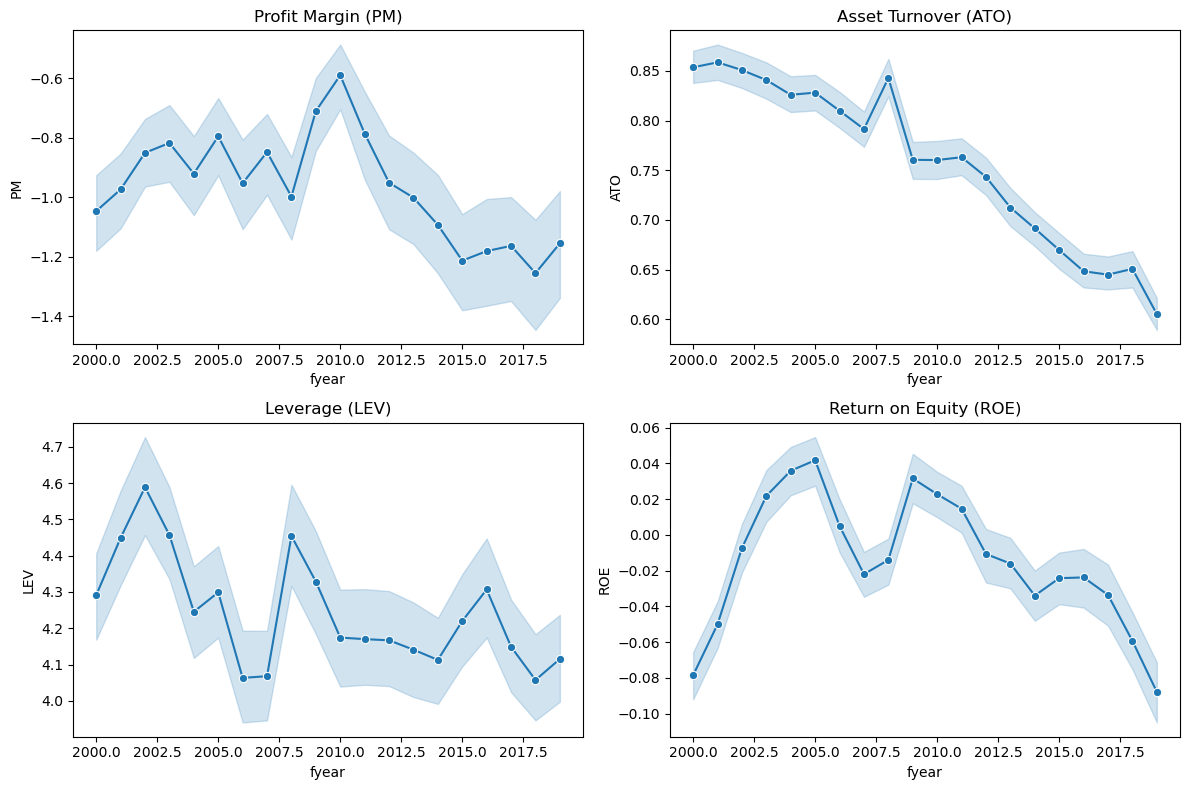

In [17]:
# Create 2x2 subplot grid
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# Individual plots
sns.lineplot(data=edata1, x='fyear', y='PM', marker='o', ax=ax[0, 0])
ax[0, 0].set_title('Profit Margin (PM)')

sns.lineplot(data=edata1, x='fyear', y='ATO', marker='o', ax=ax[0, 1])
ax[0, 1].set_title('Asset Turnover (ATO)')

sns.lineplot(data=edata1, x='fyear', y='LEV', marker='o', ax=ax[1, 0])
ax[1, 0].set_title('Leverage (LEV)')

sns.lineplot(data=edata1, x='fyear', y='ROE', marker='o', ax=ax[1, 1])
ax[1, 1].set_title('Return on Equity (ROE)')

# Improve layout
plt.tight_layout()
plt.show()

###### Visualisations: 

In order to get an understanding of how PM, ATO and LEV might impact companies’ future earnings (ROE) all variables where time trends were plotted. Each key variable is grouped by year and plotted over the mean of each variable from fyear 2000 to 2020 to see how variables have trended over time on average. 

Time trends for these variables show that average return of equities of companies in our dataset were positive between 2002 to 2006, and again in 2008 to 2011 with a short sting of being negative from 2007 – 2008. Prior to 2002 ROE was negative but trending positively, and after 2010 ROE has generally been negatively and trending further negatively. Leverage (sales divided by total assets) on average for companies is positive and following a similar pattern as ROE suggesting it likely has a significant impact on ROE trends. Profit margin has on average always been negative and quite volatile from 2000 to 2010. Additionally PM has trended trended very negatively since 2010 which likely also has a significant causality of ROE being negative and trending that way since 2010. Lastly, ATO on average for all companies has always been positively but also has been consistently on a  downward trajectory with the exception of 2007. 


In [19]:
# Descriptive statistics 
edata1[['ROE', 'PM', 'ATO', 'LEV']].describe()

,ROE,PM,ATO,LEV
count,133048.000000,133048.000000,133048.000000,133048.000000
mean,-0.013670,-0.956439,0.766254,4.252755
std,0.591186,6.072321,0.760396,5.444225
min,-3.437289,-55.653851,0.005659,1.032444
25%,-0.067873,-0.039709,0.178278,1.514355
50%,0.075130,0.044891,0.557524,2.258768
75%,0.159353,0.123144,1.090184,4.166679
max,2.184302,1.175994,3.861012,39.376767


###### Descriptive statistics & coefficients:

This report utilises the .corr() method from python to calculate the correlation coefficients between key variables. By quantifying the strength and direction of the linear relationships between key variables and applying their relationships to the conceptual regression model we can evaluate the significance each DuPont component has on predicting companies future earnings.  


In [21]:
# Correlation matrix 
corr1 = edata1[['ROE', 'PM', 'ATO', 'LEV']].corr()
corr1

,ROE,PM,ATO,LEV
ROE,1.000000,0.297395,0.119174,0.092021
PM,0.297395,1.000000,0.150506,0.060301
ATO,0.119174,0.150506,1.000000,-0.158245
LEV,0.092021,0.060301,-0.158245,1.000000


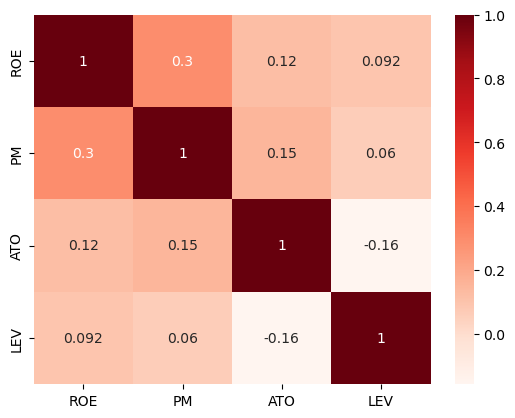

In [22]:
import matplotlib.pyplot as plt 
import seaborn as sns

%matplotlib inline 

sns.heatmap(corr1, cmap = 'Reds', annot = True)
plt.show()

In [23]:
from scipy.stats import pearsonr

rho = edata1[['ROE', 'PM', 'ATO', 'LEV']].corr()
pval = edata1[['ROE', 'PM', 'ATO', 'LEV']].corr(method = lambda x, y: pearsonr(x, y)[1]) - np.eye(*rho.shape)

# use * to indicate statistical significance
p = pval.applymap(lambda x: ''.join(['*' for t in [.05, .01, .001] if x<=t]))
rho.round(2).astype(str) + p
                                                                                   

,ROE,PM,ATO,LEV
ROE,1.0***,0.3***,0.12***,0.09***
PM,0.3***,1.0***,0.15***,0.06***
ATO,0.12***,0.15***,1.0***,-0.16***
LEV,0.09***,0.06***,-0.16***,1.0***


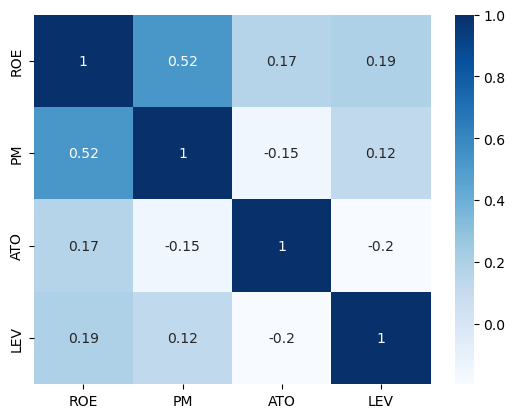

In [24]:
corr2 = edata1[['ROE', 'PM', 'ATO', 'LEV']].corr(method = 'spearman')
sns.heatmap(corr2, cmap = 'Blues', annot = True)

plt.show()                                                

###### Descriptive Statistics & Correlation Coefficients (cont.): 

The .corr() method from Pandas package does not produce p-values of each coefficient to evaluate the significance of each variables relationship. Therefore, the stats function from Scipy package has been employed to display correlation coefficients significance to complete this task.

Correlation coefficients were calculated for DuPont’s components using both Pearson and Spearman methods. From the pearson coefficient analysis we can see that ROE is positively related to PM, ATO and LEV suggesting that when these ratios of key DuPonts components increase, companies are likely to have a higher earnings in year t+1. With the exception of the correlation between ATO and LEV all coefficients are positive, and all are quite small. Furthermore, using the stats package from Scipy we can see that all coefficients are statistically significant in their relationship. 

These findings are also backed up when comparing the Spearman method of analysing correlation coefficients with the unique difference in ATO and PM correlation coefficients also being negatively correlated. 

Using the Pearson correlation coefficient analysis, the conceptual regression model becomes: 

$N_{t+1} = 0.3 PM_{t} + 0.12 ATO_{t} + 0.092 LEV_{t}$

##### Simple Models 

###### EPS & simple model methods
EPS is another reliable method of reporting companies’ financial earnings and is one of the most important accounting metrics reporting in financial statements. EPS - calculated as net income divided by common shares outstanding – provides a quick a reliable way of interpreting companies profitability. Generally, EPS indicates how much profit is attributed to each individual share of stock. Positive EPS indicates that the company is making a profit and negative EPS will indicate if a company is making a net loss. The following section will aim to forecast EPS using two simple models – Random Walk model and Moving Average Model. 

Firstly, the accounting data is copied once again to maintain the original dataset and assigned to eps dataset. The EPS variable is then calculated as net income divided by common shares outstanding. Following this, only the relevant variables for these simple models are selected namely 'gvkey', 'datadate', 'fyear', 'ni', 'csho', 'eps' and 'at'. To deal with extreme outliers, the data is winsorised so that outliers are reset to either the 99th or 1st percentiles. The data was grouped by gvkey to create forecast of EPS values for each company in the dataset. 

Random walk models are created for 1, 2 and 3 years ahead by taking the eps value at t+1,2 or 3 past observation t. This is computed using the .shift() function in python. Error values are then calculated for each random walk model. 

Similarly, moving average models are created for 2, 3 and 5 years averages by taking the means of EPS values for 2, 3 or 5 EPS past EPS values to forecast the next EPS value. This was completed using the .rolling() python function. Once again, error values were calculated for each moving average model. 

##### Random Walk

In [29]:
eps = acc.copy()
eps['eps'] = eps.ni/eps.csho

eps1 = eps[['gvkey', 'datadate', 'fyear', 'ni', 'csho', 'eps', 'at']]
eps1.head()

,gvkey,datadate,fyear,ni,csho,eps,at
0,1004,20010531,2000,18.531,26.937,0.687939,701.854
1,1004,20020531,2001,-58.939,31.870,-1.849357,710.199
2,1004,20030531,2002,-12.410,31.851,-0.389627,686.621
3,1004,20040531,2003,3.504,32.245,0.108668,709.292
4,1004,20050531,2004,15.453,32.586,0.474222,732.230


In [30]:
# Convert DataDate into datetime
eps1['datadate'] = pd.to_datetime(eps1['datadate'].astype(str))
eps1.head()

,gvkey,datadate,fyear,ni,csho,eps,at
0,1004,2001-05-31,2000,18.531,26.937,0.687939,701.854
1,1004,2002-05-31,2001,-58.939,31.870,-1.849357,710.199
2,1004,2003-05-31,2002,-12.410,31.851,-0.389627,686.621
3,1004,2004-05-31,2003,3.504,32.245,0.108668,709.292
4,1004,2005-05-31,2004,15.453,32.586,0.474222,732.230


In [31]:
# Winsorise extreme EPS values 
eps2 = winsorize(df = eps1, vars = ['eps', 'ni', 'csho', 'at'])

In [32]:
print(f'Unique companies in the data = {len(eps2['gvkey'].unique())}.')

Unique companies in the data = 21735.


In [33]:
pd.set_option('display.float_format', lambda x: f' {x:,.3f}')
eps2.describe()

,gvkey,datadate,fyear,ni,csho,eps,at
count,"285,491.000",285491,"285,491.000","285,491.000","186,412.000","186,410.000","285,491.000"
mean,"80,522.683",2011-02-19 14:13:59.992854784,"2,010.169",119.839,126.791,2.543,"4,799.500"
min,"1,004.000",2000-06-30 00:00:00,"2,000.000",-721.779,0.006,-20.194,0.008
25%,"18,560.000",2005-09-30 00:00:00,"2,005.000",-7.264,12.207,-0.205,28.228
50%,"62,178.000",2011-09-30 00:00:00,"2,011.000",0.574,33.695,0.097,235.635
75%,"147,103.000",2016-06-30 00:00:00,"2,016.000",36.516,89.944,1.302,"1,567.180"
max,"351,590.000",2021-05-31 00:00:00,"2,020.000","4,029.000","2,393.781",185.281,"146,227.025"
std,"70,184.924",NaN,6.187,548.301,325.769,19.603,"18,307.552"


After the eps data has been winsorised to deal with outlier balues, from the output above it can be seen: 
* There are 285,491 firm-year observations in the data
* The sample period spans from 2000 to 2020
* The mean EPS is 2.543 dollars but the median is 97 cents
* The 25th percentile of EPS is -20.5 cents and the 75th percentile is 1.30 dollars

In [35]:
# Random Walk Construct forecasts 
eps2 = eps2.sort_values(['gvkey', 'fyear'])

# form groups and then take lags 
eps2['eps1'] = eps2.groupby(['gvkey'])['eps'].shift(1)
eps2['year1'] = eps2.groupby(['gvkey'])['fyear'].shift(1)

eps2['eps2'] = eps2.groupby(['gvkey'])['eps'].shift(2)
eps2['year2'] = eps2.groupby(['gvkey'])['fyear'].shift(2)

eps2['eps3'] = eps2.groupby(['gvkey'])['eps'].shift(3)
eps2['year3'] = eps2.groupby(['gvkey'])['fyear'].shift(3)

eps2 = eps2[['gvkey', 'fyear', 'datadate', 'ni', 'csho', 'eps', 'at', 'eps1', 'year1', 'eps2', 'year2', 'eps3', 'year3']]
eps2.head()

,gvkey,fyear,datadate,ni,csho,eps,at,eps1,year1,eps2,year2,eps3,year3
0,1004,2000,2001-05-31,18.531,26.937,0.688,701.854,NaN,NaN,NaN,NaN,NaN,NaN
1,1004,2001,2002-05-31,-58.939,31.870,-1.849,710.199,0.688,"2,000.000",NaN,NaN,NaN,NaN
2,1004,2002,2003-05-31,-12.410,31.851,-0.390,686.621,-1.849,"2,001.000",0.688,"2,000.000",NaN,NaN
3,1004,2003,2004-05-31,3.504,32.245,0.109,709.292,-0.390,"2,002.000",-1.849,"2,001.000",0.688,"2,000.000"
4,1004,2004,2005-05-31,15.453,32.586,0.474,732.230,0.109,"2,003.000",-0.390,"2,002.000",-1.849,"2,001.000"


In [36]:
# Calculate forecast errors for random walk model
eps2['rw1'] = eps2.eps1
eps2['error_rw1'] = abs((eps2.eps - eps2.eps1)/eps2.eps)

eps2['rw2'] = eps2.eps2
eps2['error_rw2'] = abs((eps2.eps - eps2.eps2)/eps2.eps)

eps2['rw3'] = eps2.eps3
eps2['error_rw3'] = abs((eps2.eps - eps2.eps3)/eps2.eps)

eps2.head()

,gvkey,fyear,datadate,ni,csho,eps,at,eps1,year1,eps2,year2,eps3,year3,rw1,error_rw1,rw2,error_rw2,rw3,error_rw3
0,1004,2000,2001-05-31,18.531,26.937,0.688,701.854,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1004,2001,2002-05-31,-58.939,31.870,-1.849,710.199,0.688,"2,000.000",NaN,NaN,NaN,NaN,0.688,1.372,NaN,NaN,NaN,NaN
2,1004,2002,2003-05-31,-12.410,31.851,-0.390,686.621,-1.849,"2,001.000",0.688,"2,000.000",NaN,NaN,-1.849,3.746,0.688,2.766,NaN,NaN
3,1004,2003,2004-05-31,3.504,32.245,0.109,709.292,-0.390,"2,002.000",-1.849,"2,001.000",0.688,"2,000.000",-0.390,4.585,-1.849,18.018,0.688,5.331
4,1004,2004,2005-05-31,15.453,32.586,0.474,732.230,0.109,"2,003.000",-0.390,"2,002.000",-1.849,"2,001.000",0.109,0.771,-0.390,1.822,-1.849,4.900


##### Moving Average 

In [38]:
# Calculate Moving Averages forecasts and erros 
eps2['mv2'] = eps2.groupby('gvkey')['eps1'].rolling(2).mean().reset_index(level=0, drop=True)
eps2['error_mv2'] = abs((eps2.eps - eps2.mv2)/eps2.eps)

eps2['mv3'] = eps2.groupby('gvkey')['eps1'].rolling(3).mean().reset_index(level=0, drop=True)
eps2['error_mv3'] = abs((eps2.eps - eps2.mv3)/eps2.eps)

eps2['mv5'] = eps2.groupby('gvkey')['eps1'].rolling(5).mean().reset_index(level=0, drop=True)
eps2['error_mv5'] = abs((eps2.eps - eps2.mv5)/eps2.eps)

eps2.head()


,gvkey,fyear,datadate,ni,csho,eps,at,eps1,year1,eps2,...,rw2,error_rw2,rw3,error_rw3,mv2,error_mv2,mv3,error_mv3,mv5,error_mv5
0,1004,2000,2001-05-31,18.531,26.937,0.688,701.854,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1004,2001,2002-05-31,-58.939,31.870,-1.849,710.199,0.688,"2,000.000",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1004,2002,2003-05-31,-12.410,31.851,-0.390,686.621,-1.849,"2,001.000",0.688,...,0.688,2.766,NaN,NaN,-0.581,0.490,NaN,NaN,NaN,NaN
3,1004,2003,2004-05-31,3.504,32.245,0.109,709.292,-0.390,"2,002.000",-1.849,...,-1.849,18.018,0.688,5.331,-1.119,11.302,-0.517,5.758,NaN,NaN
4,1004,2004,2005-05-31,15.453,32.586,0.474,732.230,0.109,"2,003.000",-0.390,...,-0.390,1.822,-1.849,4.900,-0.140,1.296,-0.710,2.497,NaN,NaN


In [39]:
# remove inf and nan values from model errors 
eps2.replace([np.inf, -np.inf], np.nan, inplace = True)
eps2.dropna(subset = ['error_rw1', 'error_rw2', 'error_rw3', 'error_mv2', 'error_mv3', 'error_mv5'], inplace = True)

# Examine forecast errors from RW & MV models 
eps2[['error_rw1', 'error_rw2', 'error_rw3', 'error_mv2', 'error_mv3', 'error_mv5']].describe()

,error_rw1,error_rw2,error_rw3,error_mv2,error_mv3,error_mv5
count,"52,554.000","52,554.000","52,554.000","52,554.000","52,554.000","52,554.000"
mean,17.037,18.299,17.662,17.218,16.678,16.152
std,"3,032.997","2,773.329","2,157.071","2,902.440","2,648.089","2,022.812"
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.165,0.239,0.294,0.196,0.220,0.259
50%,0.460,0.606,0.707,0.501,0.546,0.609
75%,1.192,1.451,1.641,1.269,1.314,1.431
max,"695,135.043","634,840.817","489,094.000","664,987.930","606,356.620","461,289.349"


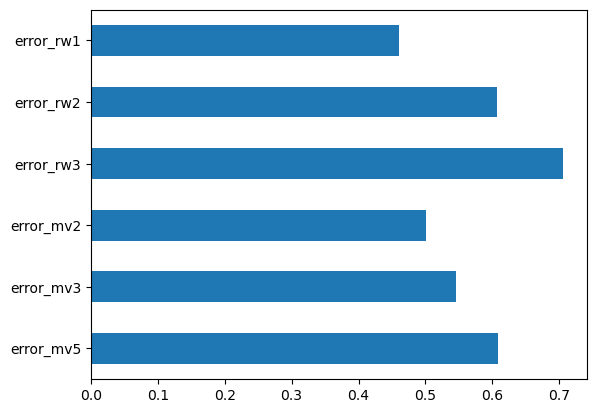

In [40]:
errors = eps2[['error_mv5', 'error_mv3', 'error_mv2','error_rw3', 'error_rw2','error_rw1']].median()
errors.plot.barh()
plt.show()

# comparing forecast errors 

Forecast errors have been calculated for all models as the absolute value of the difference between actual EPS and the forecasted EPS, divided by EPS. A forecast error closer to 0 will represent a more accurate model as there is very small difference between the Actual EPS value and the forecast. 

From the mean forecast above we can see that the average EPS forecast error is aruond 17, meaning that the error of the forecasted value is approximatly 17 times the actual EPS value accross the board. This does seem like a large error, however this is coming from quite simple models. 

Lookong at the random walk models we can see that rw1 avg error forecast is the smallest at 17.04. rw2 model has the largest mean error forecast of 18.29 times different from actual EPS. Additionally, rw1 has the smallest median error forecast also at 46% of the actual EPS. These error forecast would be expected as the longer a forecast horizon, the more uncertainty is involved and creates difficulty in model prediction accuracy. As rw1 has the smallest forecast horizon of the 3 random walk models it checks out that it has the smallest forecat error. 

From the moving average model the forecast error decreases with the number of years the model is averaging. MV2 mean forecast error is 17.21, MV3 mean forecast error is 16.67 and lastly MV5 forecast error is 16.15. This also is consistent with statistical reasoning that the model that incorporates the most amount of data produces the most accurate model. For example, as MV5 is taking the average of 5 years, whereas MV2 only takes the average of the last 2, MV5 is more likely going to be more accurate as it takes in more data. 

Finally, when comparing the avg forecast error for the mv5 model (16.15) against the most accurate random walk model, rw1 (17.01) we can see that MV5 still produces the lowest forecast error. Once again this is to be expected as rw1 takes in less data into the model than the 5 year moving average model. However, the median error forecast from RW1 is lower than median forecast error for the MV5 model at 46% and 60.8% respectively. This is likely due to the 5 year moving average model having a much larger forecast horizon than the RW1 model. For example RW1 model only has a 1 year forecast horizon, whereas MV5 takes into account last 5 year EPS average and therefore has a 5 year forecast horizon. 

In [42]:
print(eps2.columns)

Index(['gvkey', 'fyear', 'datadate', 'ni', 'csho', 'eps', 'at', 'eps1',
       'year1', 'eps2', 'year2', 'eps3', 'year3', 'rw1', 'error_rw1', 'rw2',
       'error_rw2', 'rw3', 'error_rw3', 'mv2', 'error_mv2', 'mv3', 'error_mv3',
       'mv5', 'error_mv5'],
      dtype='object')


In [43]:
# Calculate the differences in forecast error between the models 
eps2['rw1_mv3'] = eps2['error_rw1'] - eps2['error_mv3']
eps2['mv3_mv5'] = eps2['error_mv3'] - eps2['error_mv5'] 
eps2['rw1_mv5'] = eps2['error_rw1'] - eps2['error_mv5'] 

eps2[['rw1_mv3', 'rw1_mv5', 'mv3_mv5']].describe()

,rw1_mv3,rw1_mv5,mv3_mv5
count,"52,554.000","52,554.000","52,554.000"
mean,0.359,0.885,0.526
std,403.907,"1,040.548",652.937
min,"-20,695.937","-32,420.824","-32,443.796"
25%,-0.300,-0.442,-0.204
50%,-0.047,-0.094,-0.032
75%,0.188,0.197,0.151
max,"88,778.423","233,845.694","145,067.271"


In [44]:
from scipy import stats
# rw1 vs mv3
rw1_mv3 = stats.ttest_1samp(eps2['rw1_mv3'], popmean = 0)
print(f'rw1 and mv3 comparison - t-stat = {rw1_mv3[0]}, p-value = {rw1_mv3[1]}.')

# rw1 vs mv5
rw1_mv5 = stats.ttest_1samp(eps2['rw1_mv5'], popmean=0)
print(f'rw1 and mv5 comparison - t-stat = {rw1_mv5.statistic:.4f}, p-value = {rw1_mv5.pvalue:.4f}')

# mv3 vs mv5
mv3_mv5 = stats.ttest_1samp(eps2['mv3_mv5'], popmean=0)
print(f'mv3 and mv5 comparison - t-stat = {mv3_mv5.statistic:.4f}, p-value = {mv3_mv5.pvalue:.4f}')

rw1 and mv3 comparison - t-stat = 0.2037682967225466, p-value = 0.8385353575629971.
rw1 and mv5 comparison - t-stat = 0.1949, p-value = 0.8454
mv3 and mv5 comparison - t-stat = 0.1846, p-value = 0.8535


Taking a further look and comparison of the three most accurate models based on mean forecast error, we compare t-statistic and p-value of rw1, mv3 and mv5. 
For rw1 and mv3 the t-stat = 0.204 and p-value = 0.84. This means that there is an 84% chance that the mean difference in forecast errors is zero. Therefore, we will fail to reject the null hypothesis at both the 1% and 5% significance levels suggesting that there is no significant difference in forecast accuracy between rw1 and mv3. 
For rw1 and mv5 the t-stat = 0.195 and p-value = 0.845. This means that there is again 84% chance that the mean difference in forecast erros is zero and we again will fail to reject the null hypothesis at both 1% and 5% significance level. This means that there is no significant difference in forecast accuracy between rw1 and mv5. 
Lastly, for mv3 and mv5 t-stat = 0.185 and p-value = 0.854. Same as both other comparisons there is 85.4% chance that mean diff in forecast error is zero and we fail to reject null hypothesis at both signidicance levels suggesting there is no difference in forecast accuracy. 

These results in forecast errors are not suprising considering all models have quite a large mean forecast error, and therefore none of the models have a very accurate prediction of EPS. 

##### Complex Models

##### OLS Regression method 

ROA is another important financial metric used interpret company earnings. Roa is calculated as net income in year t+1 divided by total assets in year t. From the DuPont analysis used in Soliman (2008) we have a conceptual regression equation used to forecast ROA which can be seen below: 

$ROA_{t+1} = \alpha_{0} + \alpha_{1}RNOA_{t} + \alpha_{2}PM_{t} + \alpha_{3}ATO_{t} + \alpha_{4}TACC_{t}+\alpha_{5}INV_{t} + \alpha_{6}AR_{t} + \alpha_{7}ETR_{t} + \alpha_{8}SGX_{t}$ 

In order to compute ROA and use it to forecast company earnings, first the accounting data was copied and assinged to acc1. To calculate all the predictor varaibles for the above conceptual regression equation, NOA was requried first. Noa is equal to operating assets minus operating liabilities. Noa was calculated from our dataset by adding 'dllt', 'dlc', 'ceq' 'mib' and subtracting 'che' and 'ivst'. Once NOA was calculated, the data was filtered for only positive sales, NOA and pre-tax income (pi) values to ensure no inf or -inf values were created. Additionally only relevant variables were selected that were required to computer all predictor variables for ROA, namely gvkey, datadate, fyear, NOA, sale, oiadp, ni, at, oancf, invt, rect, txt, pi, xsga. Missing values were dropped from the data. 

After initial data preparation, key financial ratios were calculated to capture firm performance and structure. These include profitability measures like RNOA (oiadp/NOA), PM (oiadp/sale), and ATO (sale/NOA), as well as working capital components scaled by NOA such as TACC (ni - oancf), INV (invt/NOA), and AR (rect/NOA). Additional ratios like ETR (txt/pi) and SGX (xsga/sale) were also computed. Finally, next year’s net income (ni_1) was generated using a forward shift by firm, and used to calculate forward-looking ROA (ROA_1 = ni_1/at).

Extreme outliers were handled by winsorising to the 99th or 1st percentile. Following this the OLS regression was able to be run using the smf function from the statsmodel package. From the OLS regression model, predicted values were able to be fitted back into the data and forecast errors calculated for analysis of model performance. 

In [48]:
# Backup accounting dataframe  create NOA variable  
acc1 = acc.copy()

# Create Net Operating Assets (NOA) variable 
acc1['NOA'] = acc1.dltt + acc1.dlc + acc1.ceq + acc1.mib - acc1.che - acc1.ivst

In [49]:
# Select relevant variables, positive Sales, NOA and pi values & drop NaN values 
acc2 = acc1.loc[(acc1.sale>0) & (acc1.NOA>0) & (acc1.pi>0)][['gvkey', 'datadate', 'fyear','NOA',
                                                            'sale', 'oiadp', 'ni', 'at', 'oancf', 'invt', 
                                                            'rect', 'txt', 'pi','xsga']].dropna().reset_index(drop=True)
acc2.sample(10)

,gvkey,datadate,fyear,NOA,sale,oiadp,ni,at,oancf,invt,rect,txt,pi,xsga
66837,200856,20081231,2008,"1,501.535",815.363,282.195,153.283,"2,268.298",150.520,43.472,101.817,-26.645,176.683,157.802
16476,13427,20191231,2019,"74,648.000","19,844.000","4,150.000","2,950.000","100,051.000","6,206.000","1,912.000","1,910.000",-598.000,"2,370.000","3,892.000"
14046,11465,20001231,2000,"3,502.000","10,325.000",807.000,367.000,"6,902.000",445.000,"1,119.000","1,748.000",200.000,580.000,"1,651.000"
1426,2049,20041231,2004,573.595,994.709,56.914,33.401,928.323,54.181,122.894,138.941,7.958,41.359,283.223
36968,61487,20121231,2012,370.693,214.064,71.162,64.882,"4,265.564",81.415,27.698,"3,146.303",-24.785,40.097,100.508
40252,63976,20030630,2003,718.881,290.174,35.893,8.799,920.150,50.683,6.616,24.591,5.508,14.307,85.983
4102,3980,20190930,2019,"139,507.000","69,570.000","12,009.000","11,054.000","193,984.000","6,606.000","6,246.000","15,481.000","3,031.000","13,944.000","11,383.000"
3714,3650,20181231,2018,"8,077.000","23,771.000","2,378.000","2,141.000","19,062.000","2,378.000","3,759.000","3,983.000",566.000,"2,753.000","3,339.000"
36859,61418,20030930,2003,10.570,15.060,0.358,0.438,12.256,0.586,0.230,0.259,0.000,0.404,7.113
1478,2073,20130331,2012,22.118,11.378,2.041,1.780,34.680,3.867,0.371,3.383,0.302,2.082,2.625


In [50]:
# Calculate the ratios 
acc2['RNOA'] = acc2.oiadp/acc2.NOA 
acc2['PM'] = acc2.oiadp/acc2.sale
acc2['ATO'] = acc2.sale/acc2.NOA
acc2['TACC'] = acc2.ni - acc2.oancf
acc2['INV'] = acc2.invt/acc2.NOA
acc2['AR'] = acc2.rect/acc2.NOA
acc2['ETR'] = acc2.txt/acc2.pi
acc2['SGX'] = acc2.xsga/acc2.sale

# Calculate RNOA_t+1 
acc2 = acc2.sort_values(by = ['gvkey', 'fyear'])
acc2['ni_1'] = acc2.groupby(['gvkey'])['ni'].shift(-1)

In [51]:
acc3 = acc2[['gvkey', 'fyear', 'RNOA', 'PM', 'ATO', 'TACC', 'INV', 'AR', 'ETR', 'SGX', 'ni_1', 'at', 'ni']]
acc3['ROA_1'] = acc3.ni_1/acc3['at']
acc3.head()

,gvkey,fyear,RNOA,PM,ATO,TACC,INV,AR,ETR,SGX,ni_1,at,ni,ROA_1
0,1004,2000,0.088,0.052,1.681,-27.562,0.616,0.221,0.084,0.110,3.504,701.854,18.531,0.005
1,1004,2003,0.041,0.032,1.272,-11.068,0.482,0.204,-1.053,0.124,44.628,709.292,3.504,0.063
2,1004,2009,0.086,0.071,1.224,-108.528,0.450,0.216,0.327,0.112,69.826,"1,501.042",44.628,0.047
3,1004,2010,0.112,0.077,1.453,-38.772,0.415,0.243,0.326,0.097,67.723,"1,703.727",69.826,0.040
4,1004,2011,0.090,0.069,1.305,-26.494,0.377,0.204,0.272,0.091,55.000,"2,195.653",67.723,0.025


In [52]:
# Examine outliers 
acc3.describe()

,gvkey,fyear,RNOA,PM,ATO,TACC,INV,AR,ETR,SGX,ni_1,at,ni,ROA_1
count,"68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","58,066.000","68,792.000","68,792.000","58,066.000"
mean,"72,051.617","2,009.771",1.248,0.058,9.209,-256.056,1.002,2.739,0.191,0.318,384.741,"10,535.783",346.350,0.064
std,"69,088.793",5.833,215.927,14.081,"1,433.211","2,348.226",184.174,111.811,11.868,10.119,"1,695.900","80,030.750","1,592.621",3.746
min,"1,004.000","2,000.000",-172.074,"-3,556.000",0.000,"-160,921.229",0.000,0.000,"-2,062.562",-16.018,"-16,053.703",0.037,"-16,053.703",-900.229
25%,"13,994.000","2,005.000",0.084,0.062,0.632,-98.062,0.006,0.110,0.133,0.106,6.481,181.039,5.096,0.018
50%,"31,227.000","2,010.000",0.147,0.122,1.448,-14.791,0.105,0.267,0.288,0.207,32.275,759.668,26.056,0.051
75%,"138,483.000","2,015.000",0.263,0.240,2.755,-0.551,0.317,0.641,0.371,0.333,152.159,"3,049.394",129.514,0.098
max,"351,590.000","2,020.000","56,612.000",12.942,"375,756.000","140,725.000","48,302.000","17,131.000","1,012.167","2,495.500","59,531.000","3,771,199.852","59,531.000",35.722


In [53]:
# Create Winsorize function 
def winsorize(df, vars):
    """Winsorize continuous variables to bring outlier values to match either 1st or 99th percentile""" 
    df = df.copy()
    for var in vars:
        lower = df[var].quantile(0.01)
        upper = df[var].quantile(0.99)
        df[var] = df[var].clip(lower = lower, upper = upper) 

    return df

In [54]:
# Winsorize continuous variables and drop missing values 
acc4 = winsorize(df = acc3, vars = ['RNOA', 'PM', 'ATO', 'TACC', 'INV', 'AR', 'ETR', 'SGX', 'ROA_1', 'ni_1'])
acc4[['RNOA', 'PM', 'ATO', 'TACC', 'INV', 'AR', 'ETR', 'SGX', 'ROA_1', 'ni', 'ni_1']].dropna()

acc4.describe()

,gvkey,fyear,RNOA,PM,ATO,TACC,INV,AR,ETR,SGX,ni_1,at,ni,ROA_1
count,"68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","68,792.000","58,066.000","68,792.000","68,792.000","58,066.000"
mean,"72,051.617","2,009.771",0.270,0.166,2.540,-211.446,0.230,1.184,0.233,0.234,322.923,"10,535.783",346.350,0.074
std,"69,088.793",5.833,0.460,0.143,3.959,762.614,0.340,2.892,0.408,0.158,985.834,"80,030.750","1,592.621",0.082
min,"1,004.000","2,000.000",-0.083,-0.090,0.094,"-5,687.725",0.000,0.001,-2.146,0.013,-19.223,0.037,"-16,053.703",-0.021
25%,"13,994.000","2,005.000",0.084,0.062,0.632,-98.062,0.006,0.110,0.133,0.106,6.481,181.039,5.096,0.018
50%,"31,227.000","2,010.000",0.147,0.122,1.448,-14.791,0.105,0.267,0.288,0.207,32.275,759.668,26.056,0.051
75%,"138,483.000","2,015.000",0.263,0.240,2.755,-0.551,0.317,0.641,0.371,0.333,152.159,"3,049.394",129.514,0.098
max,"351,590.000","2,020.000",3.459,0.614,28.824,683.806,2.056,20.348,1.927,0.729,"7,033.973","3,771,199.852","59,531.000",0.471


In [55]:
import statsmodels.formula.api as smf 
formula = 'ROA_1 ~ RNOA + PM + ATO + TACC + INV + AR + ETR + SGX'
model = smf.ols(formula, data = acc4)
result = model.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                  ROA_1   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1945.
Date:                Mon, 02 Jun 2025   Prob (F-statistic):               0.00
Time:                        19:55:59   Log-Likelihood:                 69706.
No. Observations:               58066   AIC:                        -1.394e+05
Df Residuals:                   58057   BIC:                        -1.393e+05
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0591      0.001     71.801      0.0

#### Forecasting ROE and Earnings 

##### Regression Results 

There were 58,066 observations used to estimate the regression for ROA_1. The R2 and adjusted R2 is 21.1% suggesting that the independent variables collecetively explain 22.1% of variations in ROA_1. The F-statistic and Prob(F-statistic) suggest that the models explanatory power is statistically significant, and therefore that the independent variables in this OLS model have a significant impact in predicting power of ROA_1. 

P-values on all independenct variables are less than 0.01, so therefore it can be concluded that the estimated coefficients in the model are not zero. The regression model fit is therefore: 
$ROA_{t+1} = 0.0591 + 0.0840RNOA_{t} + 0.0365PM_{t} - 0.0009ATO_{t} + 4.235e-06 TACC_{t}+ 0.0046INV_{t} - 0.0102AR_{t} - 0.0125ETR_{t} + 0.0101SGX_{t}$ 

We can now see that RNOA, PM, TACC, INV and SGX are all positivley related to ROA_1, and ATO, AR and ETR are negatively related. 

In [58]:
result.fittedvalues.head()

0    0.067
1    0.077
2    0.064
3    0.066
4    0.065
dtype: float64

In [59]:
# Select relevant variables from orignal dataset 
acc5 = acc4[['gvkey', 'fyear', 'RNOA', 'ni', 'PM', 'ATO', 'INV', 'AR', 'ETR', 'SGX', 'at', 'ni_1', 'ROA_1',]]

# Merge Predicted ROA with orignal data 
pred = pd.DataFrame(result.fittedvalues, columns = ['fitted_ROA']) 
acc6 = pd.merge(acc5, pred, left_index = True, right_index = True)
acc6.head()

,gvkey,fyear,RNOA,ni,PM,ATO,INV,AR,ETR,SGX,at,ni_1,ROA_1,fitted_ROA
0,1004,2000,0.088,18.531,0.052,1.681,0.616,0.221,0.084,0.110,701.854,3.504,0.005,0.067
1,1004,2003,0.041,3.504,0.032,1.272,0.482,0.204,-1.053,0.124,709.292,44.628,0.063,0.077
2,1004,2009,0.086,44.628,0.071,1.224,0.450,0.216,0.327,0.112,"1,501.042",69.826,0.047,0.064
3,1004,2010,0.112,69.826,0.077,1.453,0.415,0.243,0.326,0.097,"1,703.727",67.723,0.040,0.066
4,1004,2011,0.090,67.723,0.069,1.305,0.377,0.204,0.272,0.091,"2,195.653",55.000,0.025,0.065


In [60]:
# develpo earnings forecasts 
acc6['pred_ni'] = acc6.fitted_ROA * acc6['at']
acc6['OLS_error'] = abs(acc6.ni_1 - acc6.pred_ni)/acc6['at']

acc7 = acc6[['OLS_error']].describe().reset_index()

# random walk model errors 
eps2['rw1_pred_ni'] = eps2.rw1 * eps2.csho
eps2['rw1_error_ni'] = abs(eps2.rw1_pred_ni - eps2.ni)/eps2['at']

eps2['rw2_pred_ni'] = eps2.rw2 * eps2.csho
eps2['rw2_error_ni'] = abs(eps2.rw2_pred_ni - eps2.ni)/eps2['at']

eps2['rw3_pred_ni'] = eps2.rw3 * eps2.csho
eps2['rw3_error_ni'] = abs(eps2.rw3_pred_ni - eps2.ni)/eps2['at']

# moving average model errors 
eps2['mv2_pred_ni'] = eps2.mv2 * eps2.csho
eps2['mv2_error_ni'] = abs(eps2.mv2_pred_ni - eps2.ni)/eps2['at'] 

eps2['mv3_pred_ni'] = eps2.mv3 * eps2.csho
eps2['mv3_error_ni'] = abs(eps2.mv3_pred_ni - eps2.ni)/eps2['at'] 

eps2['mv5_pred_ni'] = eps2.mv5 * eps2.csho
eps2['mv5_error_ni'] = abs(eps2.mv5_pred_ni - eps2.ni)/eps2['at'] 

eps3 = eps2[['rw1_error_ni', 'rw2_error_ni', 'rw3_error_ni', 'mv2_error_ni', 'mv3_error_ni', 'mv5_error_ni']].describe().reset_index()

acc6[['OLS_error']].describe()

,OLS_error
count,"58,066.000"
mean,0.057
std,0.724
min,0.000
25%,0.018
50%,0.035
75%,0.056
max,163.054


In [61]:
errors_table = pd.merge(acc7, eps3, on = 'index', how = 'outer')
row_order = ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
errors_table = errors_table.set_index('index').loc[row_order].reset_index()
errors_table.set_index('index', inplace = True)
errors_table

,OLS_error,rw1_error_ni,rw2_error_ni,rw3_error_ni,mv2_error_ni,mv3_error_ni,mv5_error_ni
index,,,,,,,
count,"58,066.000","52,554.000","52,554.000","52,554.000","52,554.000","52,554.000","52,554.000"
mean,0.057,7.478,5.542,7.122,6.195,5.921,6.489
std,0.724,633.044,293.067,353.277,406.381,331.781,267.955
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.018,0.006,0.008,0.009,0.006,0.007,0.008
50%,0.035,0.024,0.031,0.035,0.026,0.028,0.031
75%,0.056,0.086,0.108,0.123,0.091,0.097,0.104
max,163.054,"122,709.274","56,931.360","50,249.327","64,034.256","54,376.786","41,366.582"


##### Examine Forecast Errors with Time series Models

To compare how well models forecast company earnings, all models were converted to predicted values of net income, and error values calculated by standardising for total assets. From the above table comparing model errors of simple models (random walk and moving average) against OLS complex model we can see that OLS Regression has a much smaller mean average error of 0.057. Therefore the OLS regression model is very close to the acual net income value and therefore is quite an accurate model for forecasting company earning as net income. Compared to the simple model where the error is at best 5.5 for all simple models.  

The median values for all models is lower than the means, especially in the simple models. This may suggest that in those simple randome walk and moving average models the distributions are skewed to the right and some very large values are inflating the means. OLS shows a tighter distribution than all simple models indicating that the mean value is good estimation of the models accuracy. 

##### Concusion
This report has demonstrated that financial statement anlaysis using methodology guided by the DuPont analysis provides valuable insights into forecasting company earnings. Multiple models such as random walk, moving average and OLS regression have been utilised to forecast financial metrics such as EPS, ROA and net income to indicate companies earnings and overall profitability. The ranodm walk and moving average models from this report offer methods to perform straightforward predictions of company earnings but ultimately their forecast errors have been recorded signficantly higher and more varialb ethan those from the more complex OLS regression model. The OLS regression model which has made use of many more statistically predictors in its equation has yielded more accurate and stable forecast for company earnings. While this may be the case in this report, OLS regression may not always be a more reliable model for predicting company earnings espeically when so many firms data is being used for forecasts. In summary, leveraging multiple financial accounting ratios has helped improve predictive power and may help both investors and business strategists to make more informed decisions. 

References: 

Soliman, M. T. (2008). The use of DuPont analysis by market participants. The Accounting Review, 83(3), 823–853. https://doi.org/10.2308/accr.2008.83.3.823

